# 03. 경영비 반영 · 물가 보정

`02_trend_weather_timing` §2의 품종별 수익성은 **매출(조수입) 기준**이었고, 장기 추세는 **명목 가격**이었습니다.
이 노트북에서는 두 가지를 보완합니다.

1. **경영비 반영 (FR-204)**: 표준소득표로 비용을 뺀 뒤 품종 순위가 어떻게 바뀌는지, 그리고 여러 해에 걸쳐 같은지
2. **물가 보정 (FR-205)**: 단가·ha당 조수입에서 소비자물가·농가 생산비 상승분을 빼도 실제로 올랐는지

| 자료 | 파일 | 출처 |
| --- | --- | --- |
| 표준소득표 2016~2024년산 (9년) | `data/external/cost/standard_income.csv` | 제주농산물수급관리센터 「감귤유통처리 분석」 참고자료. 2017·2022~2024년산은 PDF 텍스트 추출, 2016·2018~2021년산은 쪽 이미지 판독(`standard_income_transcribed.csv`) |
| 연평균 CPI (2020=100) | `data/external/cpi/cpi_annual.csv` | 국가지표체계(2015~2025), 2004~2014는 제3자 표를 공식 상승률과 대조 |
| 농가구입가격지수 (2020=100, 분기) | `data/external/cpi/kosis_farm_purchase_price_quarterly.csv` | KOSIS 농가판매 및 구입가격조사 (2005.1/4~2026.3/4) |

자세한 검증 내용은 [`data/external/README_cost_cpi.md`](../data/external/README_cost_cpi.md)에 있습니다.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from jeju_citrus.config import FIGURES_DIR
from jeju_citrus.data import (
    load_cpi,
    load_farm_purchase_index,
    load_processed,
    load_standard_income,
    load_standard_income_items,
)
from jeju_citrus.features import COST_ITEM_GROUPS, cost_price_index, cost_weights, deflate, income_per_ha
from jeju_citrus.visualization import set_style

set_style()
pd.set_option("display.float_format", "{:,.1f}".format)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 범주형 색: 고정 순서 (품종 → 색은 모든 그래프에서 같음)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
VARIETIES = ["노지온주", "하우스온주", "월동온주", "한라봉", "천혜향", "레드향", "황금향"]
VCOLOR = dict(zip(VARIETIES, PALETTE))
C1, C2, C3 = PALETTE[:3]
MUTED = "#52514e"

prod = load_processed("citrus_production_yearly")
cpi = load_cpi()
std_all = income_per_ha(load_standard_income())
std = std_all[std_all["산지연도"] == 2024].reset_index(drop=True)

## 1. 경영비 반영: 비용을 빼면 품종 순위가 바뀌는가?

표준소득표 단위는 **만원/10a**입니다. 프로젝트의 `ha당_조수입_백만원`과 맞추기 위해 **백만원/ha**로 바꿨습니다(× 0.1).

- **소득** = 총수입 − 경영비. 자가노동·자기자본 보상이 아직 남아 있어서 **순이익이 아닙니다**.
- **순수익** = 총수입 − 생산비(경영비 + 자가노동비 + 자본용역비).
- 품종 대응: 시설감귤 → 하우스온주, 하우스월동감귤 → 월동온주. 가온 여부·시설 수준은 맞췄는지 확인하지 못했습니다.

### 1.1 2024년산

In [2]:
cols = ["대응품종", "총수입_백만원_ha", "경영비_백만원_ha", "소득_백만원_ha", "순수익_백만원_ha", "경영비율_퍼센트", "총수입_순위", "소득_순위"]
std[cols].sort_values("소득_순위").reset_index(drop=True)

,대응품종,총수입_백만원_ha,경영비_백만원_ha,소득_백만원_ha,순수익_백만원_ha,경영비율_퍼센트,총수입_순위,소득_순위
0,천혜향,197.2,60.5,136.7,109.0,30.7,2,1
1,하우스온주,233.4,123.9,109.4,79.3,53.1,1,2
2,한라봉,151.5,53.0,98.5,51.2,35.0,4,3
3,월동온주,149.1,52.3,96.9,62.5,35.0,5,4
4,황금향,157.8,80.0,77.7,18.1,50.7,3,5
5,레드향,139.1,63.4,75.7,37.2,45.6,6,6
6,노지온주,45.4,16.7,28.7,6.4,36.8,7,7


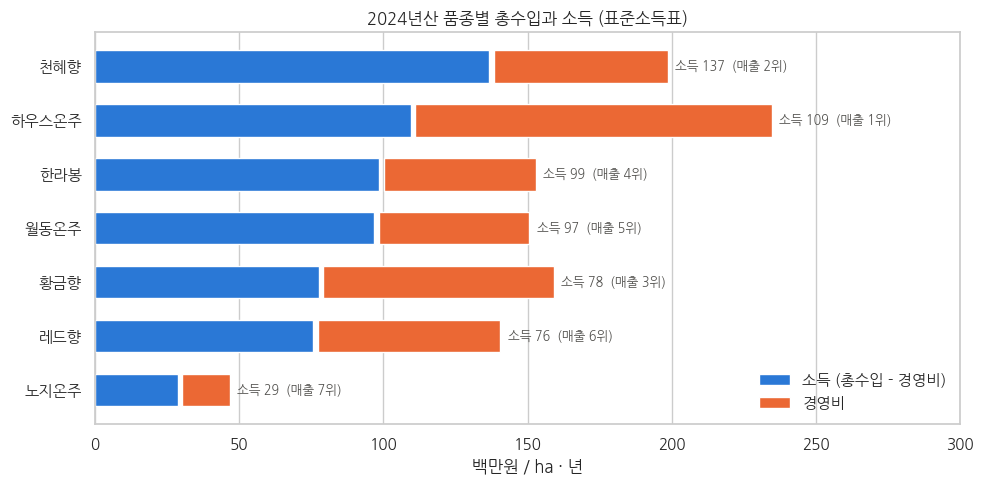

In [3]:
t = std.sort_values("소득_백만원_ha")
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(t))
ax.barh(y, t["소득_백만원_ha"], color=C1, height=0.6, label="소득 (총수입 - 경영비)")
ax.barh(y, t["경영비_백만원_ha"], left=t["소득_백만원_ha"] + 1.5, color=C2, height=0.6, label="경영비")
for yi, (inc, cost, rk) in enumerate(zip(t["소득_백만원_ha"], t["경영비_백만원_ha"], t["총수입_순위"])):
    ax.text(inc + cost + 4, yi, f"소득 {inc:.0f}  (매출 {rk}위)", va="center", fontsize=9, color=MUTED)
ax.set_yticks(y, t["대응품종"])
ax.set_xlabel("백만원 / ha · 년")
ax.set_xlim(0, 300)
ax.set_title("2024년산 품종별 총수입과 소득 (표준소득표)")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_standard_income_2024.png", dpi=150)
plt.show()

**관찰 (2024년산)**

- 매출 1위는 하우스온주(233백만원/ha)입니다. 하지만 경영비 비율이 53%로 높아서 소득으로는 **천혜향(137)이 1위**입니다.
- 황금향은 매출 3위에서 소득 5위로 내려갑니다(경영비율 51%).
- 생산비 전체를 빼면 노지온주는 **6.4백만원/ha(총수입의 14%)** 만 남습니다. 황금향도 18백만원/ha(11%)로 낮습니다.

### 1.2 여러 해에 걸쳐 같은가? (2016~2024년산, 9년)

레드향 표는 2020년산부터, 황금향 표는 2022년산부터 실렸습니다. 2016·2018~2021년산은 쪽 이미지를 보고 옮겼고, 모든 표가 `소득 = 총수입 − 경영비`, `생산비 = 경영비 + 자가노동비 + 자본용역비` 검산을 통과했습니다(원문 오기 2건은 정정, `비고` 컬럼 참고).

In [4]:
rank = std_all.pivot(index="대응품종", columns="산지연도", values="소득_순위").reindex(VARIETIES)
inc_real = std_all.assign(실질소득=deflate(std_all["소득_백만원_ha"], std_all["산지연도"], cpi))
real = inc_real.pivot(index="대응품종", columns="산지연도", values="실질소득").reindex(VARIETIES)
print("소득 순위 (같은 해 안에서)")
display(rank)
print("실질 소득, 백만원/ha (2020년 물가)")
display(real)
print("경영비율 %")
display(std_all.pivot(index="대응품종", columns="산지연도", values="경영비율_퍼센트").reindex(VARIETIES).round(0))

소득 순위 (같은 해 안에서)


산지연도,2016,2017,2018,2019,2020,2021,2022,2023,2024
대응품종,,,,,,,,,
노지온주,5.0,5.0,5.0,5.0,6.0,6.0,7.0,7.0,7.0
하우스온주,1.0,1.0,1.0,1.0,1.0,3.0,1.0,3.0,2.0
월동온주,3.0,4.0,3.0,4.0,5.0,5.0,6.0,4.0,4.0
한라봉,4.0,3.0,4.0,3.0,4.0,4.0,5.0,2.0,3.0
천혜향,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,1.0
레드향,NaN,NaN,NaN,NaN,3.0,2.0,4.0,5.0,6.0
황금향,NaN,NaN,NaN,NaN,NaN,NaN,3.0,6.0,5.0


실질 소득, 백만원/ha (2020년 물가)


산지연도,2016,2017,2018,2019,2020,2021,2022,2023,2024
대응품종,,,,,,,,,
노지온주,29.3,31.1,24.3,16.8,21.6,24.9,17.2,29.5,25.1
하우스온주,158.7,125.9,121.3,142.7,136.7,117.7,110.4,99.8,95.8
월동온주,65.8,50.0,48.0,38.1,31.1,45.1,51.4,98.2,84.8
한라봉,63.9,61.1,43.7,61.0,90.3,108.0,85.1,105.0,86.3
천혜향,139.1,102.6,76.9,81.7,104.9,149.4,109.3,147.7,119.7
레드향,NaN,NaN,NaN,NaN,93.7,138.5,92.0,94.0,66.3
황금향,NaN,NaN,NaN,NaN,NaN,NaN,102.7,67.1,68.1


경영비율 %


산지연도,2016,2017,2018,2019,2020,2021,2022,2023,2024
대응품종,,,,,,,,,
노지온주,27.0,28.0,33.0,47.0,40.0,37.0,45.0,37.0,37.0
하우스온주,41.0,48.0,49.0,44.0,46.0,52.0,55.0,56.0,53.0
월동온주,44.0,48.0,49.0,57.0,65.0,54.0,49.0,34.0,35.0
한라봉,48.0,52.0,57.0,48.0,36.0,36.0,38.0,37.0,35.0
천혜향,28.0,35.0,42.0,43.0,35.0,29.0,39.0,30.0,31.0
레드향,NaN,NaN,NaN,NaN,39.0,27.0,39.0,36.0,46.0
황금향,NaN,NaN,NaN,NaN,NaN,NaN,45.0,59.0,51.0


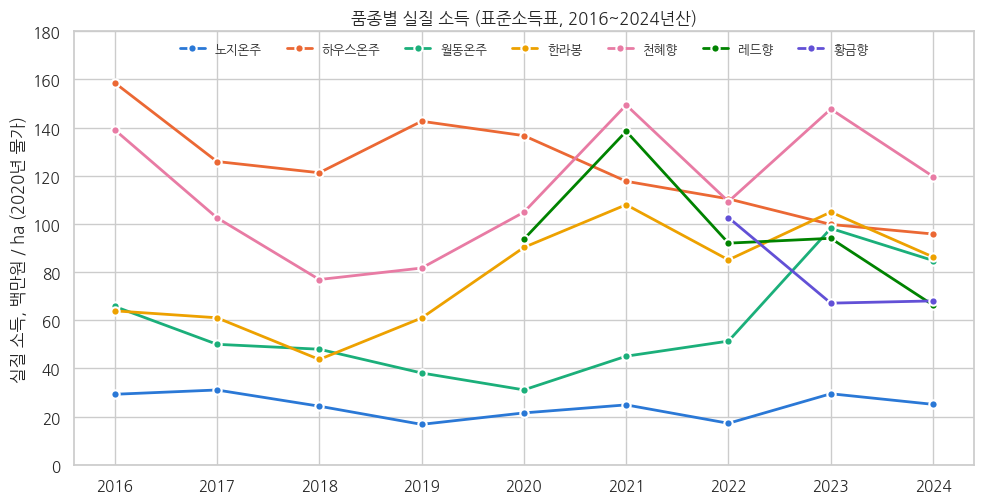

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
for v in VARIETIES:
    s = real.loc[v].dropna()
    ax.plot(s.index, s.values, color=VCOLOR[v], linewidth=2, marker="o", markersize=6,
            markeredgecolor="white", markeredgewidth=1.5, label=v)
ax.set_xticks(real.columns)
ax.set_ylim(0, 180)
ax.set_ylabel("실질 소득, 백만원 / ha (2020년 물가)")
ax.set_title("품종별 실질 소득 (표준소득표, 2016~2024년산)")
ax.legend(loc="upper center", frameon=False, ncol=7, fontsize=9, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_income_by_year.png", dpi=150)
plt.show()

**관찰 (9년)**

- **하우스온주(시설감귤)는 9년 중 6년 소득 1위**였습니다(2016~2020, 2022년). 하지만 실질 소득은 159 → 96백만원/ha로 **꾸준히 줄었습니다**(2016~18 평균 대비 2022~24 평균 −25%). 경영비율이 41% → 53~56%로 오른 것이 주된 이유입니다. 경영비 중 가장 큰 항목은 난방용 수도광열비(10a당 447~591만원, 2022년산이 가장 높음)입니다.
- **천혜향은 9년 모두 소득 2위 안**에 들었고, 2021·2023·2024년에는 1위였습니다. 가장 안정적인 상위 품종입니다.
- **한라봉(+64%)과 월동온주(+43%)는 실질 소득이 늘었습니다**(2016~18 → 2022~24 평균). 한라봉은 경영비율이 48~57% → 35~38%로 내려갔습니다.
- **노지온주는 9년 내내 꼴찌**입니다. 실질 소득은 17~31백만원/ha 사이에서 오르내릴 뿐 추세가 없습니다(−15%). 생산비 전체를 빼면 **2019·2022년산은 적자**였고, 순수익은 단가가 높았던 해(2016·2017·2023년)에만 10a당 100만원 안팎입니다.
- 황금향은 자료가 3년뿐이지만 순위가 3위 → 6위 → 5위로 흔들리고, 경영비율이 45~59%로 만감류 중 가장 높습니다.

### 1.3 표준소득표의 총수입은 제주 평균과 맞는가?

표준소득표는 **표본 농가 조사값**이고, 프로젝트의 `ha당_조수입`은 **제주 전체 조수입 ÷ 재배면적**입니다.

In [6]:
ratio = std_all[["산지연도", "대응품종", "총수입_백만원_ha"]].copy()
ratio["프로젝트"] = [prod.set_index(["품종", "연도"])["ha당_조수입_백만원"].get((v, y))
                    for v, y in zip(ratio["대응품종"], ratio["산지연도"])]
ratio["표준 ÷ 프로젝트"] = ratio["총수입_백만원_ha"] / ratio["프로젝트"]
ratio.pivot(index="대응품종", columns="산지연도", values="표준 ÷ 프로젝트").reindex(VARIETIES).round(2)

산지연도,2016,2017,2018,2019,2020,2021,2022,2023,2024
대응품종,,,,,,,,,
노지온주,1.3,1.2,1.1,1.2,1.1,1.2,1.0,1.2,1.0
하우스온주,1.0,0.9,0.9,0.9,0.9,1.0,1.1,1.0,1.2
월동온주,1.4,1.1,1.0,1.1,1.2,1.2,1.3,1.4,1.2
한라봉,1.3,1.6,1.2,1.5,1.7,1.9,1.7,1.8,1.5
천혜향,1.1,2.2,1.9,1.9,1.8,2.0,1.7,1.5,1.5
레드향,NaN,NaN,NaN,NaN,1.9,1.9,1.7,1.4,1.3
황금향,NaN,NaN,NaN,NaN,NaN,NaN,3.7,2.4,2.1


**관찰**: 노지온주와 하우스온주는 0.88~1.30배(평균 1.06배)로 제주 평균과 비슷합니다. 반면 **만감류는 9년 동안 1.14~3.71배(중앙값 1.73배)로 매번 높습니다**. 황금향은 2022년 3.7배입니다.
한 해만 그런 것이 아니므로 **표본 농가가 제주 평균보다 잘하는 농가**이거나, 면적 기준(수확 면적 vs 아직 수확하지 못하는 어린 나무를 포함한 전체 재배면적)이 다를 가능성이 큽니다.
2.2에서 보듯 만감류는 2017년 이후 재배면적이 크게 늘었습니다. 그만큼 아직 수확하지 못하는 어린 과원이 전체 면적에 섞여 있을 수 있습니다.
따라서 **표준표 소득을 제주 평균 농가 소득으로 읽으면 만감류를 과대평가하게 됩니다**.

### 1.4 제주 평균 매출에 경영비를 적용하면? (2024년산 민감도)

어느 가정이 맞는지 알 수 없어서 둘 다 계산했습니다.

- **A. 경영비 금액 그대로**: 비용은 매출과 상관없이 표준표 금액만큼 든다고 가정
- **B. 경영비 비율 적용**: 매출이 낮으면 비용도 같은 비율로 낮다고 가정

In [7]:
p24 = prod[prod["연도"] == 2024].set_index("품종")["ha당_조수입_백만원"]
sens = std[["대응품종", "소득_백만원_ha", "경영비_백만원_ha", "경영비율_퍼센트"]].copy()
sens["프로젝트_매출"] = sens["대응품종"].map(p24)
sens["A_금액차감"] = sens["프로젝트_매출"] - sens["경영비_백만원_ha"]
sens["B_비율차감"] = sens["프로젝트_매출"] * (1 - sens["경영비율_퍼센트"] / 100)
sens = sens.rename(columns={"소득_백만원_ha": "표준표_소득"})
for c in ["표준표_소득", "A_금액차감", "B_비율차감"]:
    sens[c + "_순위"] = sens[c].rank(ascending=False).astype(int)
sens[["대응품종", "프로젝트_매출", "표준표_소득", "A_금액차감", "B_비율차감",
      "표준표_소득_순위", "A_금액차감_순위", "B_비율차감_순위"]].sort_values("B_비율차감", ascending=False)

,대응품종,프로젝트_매출,표준표_소득,A_금액차감,B_비율차감,표준표_소득_순위,A_금액차감_순위,B_비율차감_순위
1,하우스온주,198.1,109.4,74.2,92.9,2,2,1
4,천혜향,131.5,136.7,71.0,91.1,1,3,2
2,월동온주,127.0,96.9,74.7,82.5,4,1,3
3,한라봉,103.4,98.5,50.5,67.3,3,4,4
5,레드향,108.4,75.7,45.1,59.0,6,5,5
6,황금향,76.7,77.7,-3.3,37.8,5,7,6
0,노지온주,46.9,28.7,30.2,29.7,7,6,7


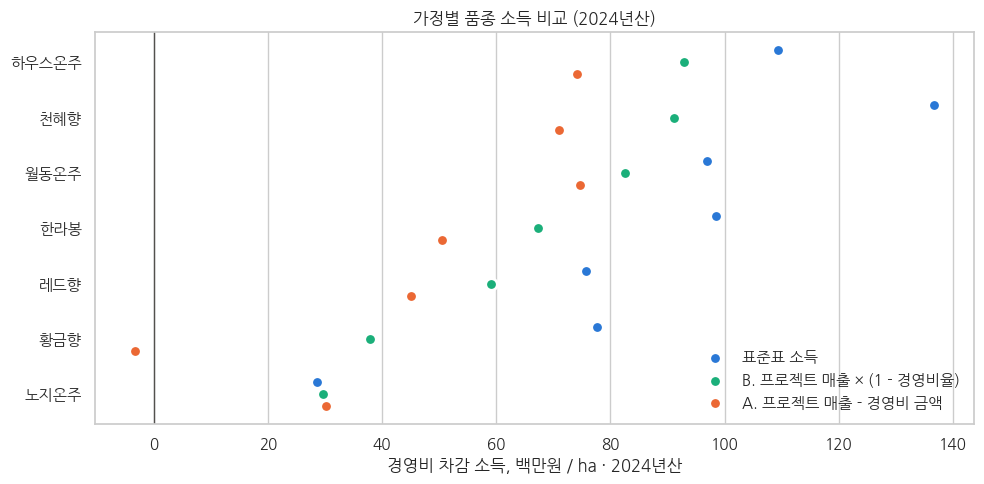

In [8]:
s = sens.sort_values("B_비율차감")
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(s))
for col, color, label, dy in [
    ("표준표_소득", C1, "표준표 소득", 0.22),
    ("B_비율차감", C3, "B. 프로젝트 매출 × (1 - 경영비율)", 0),
    ("A_금액차감", C2, "A. 프로젝트 매출 - 경영비 금액", -0.22),
]:
    ax.scatter(s[col], y + dy, s=70, color=color, edgecolor="white", linewidth=2, label=label, zorder=3)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, s["대응품종"])
ax.set_xlabel("경영비 차감 소득, 백만원 / ha · 2024년산")
ax.set_title("가정별 품종 소득 비교 (2024년산)")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_income_sensitivity.png", dpi=150)
plt.show()

**관찰**

- 제주 평균 매출로 바꾸면 **월동온주·하우스온주·천혜향이 70~93백만원/ha로 비슷해지고**, 이 셋의 순위는 가정에 따라 바뀝니다.
- 황금향은 A 가정에서 소득이 **−3백만원/ha**입니다. 평균 매출로는 표준 경영비를 감당하지 못할 수 있습니다.
- 노지온주는 어떤 방법으로 계산해도 30백만원/ha 안팎으로, 상위권(월동·하우스·천혜향)의 절반 이하입니다.

### 1장 한계

- 2023년산은 품종명 글꼴이 깨져 있어 **표 순서로 품종을 붙였습니다**. 다른 8개 연도는 표 순서가 모두 같았고, 2023년산의 단가·노동시간·경영비 패턴도 다른 연도와 맞습니다.
- 2016·2018~2021년산은 사람이 아닌 모델이 쪽 이미지를 읽고 옮긴 값입니다. 두 가지 검산을 모두 통과했지만, 검산에 쓰이지 않는 항목(수량·단가·자가노동시간)은 오독이 남아 있을 수 있습니다.
- 같은 농가가 품종을 바꿨을 때의 효과가 아닙니다. 전환 비용(묘목·시설 투자, 나무가 자라 수확하기까지의 공백)도 빠져 있습니다.
- 1.3에서 보듯 표준표 총수입과 제주 평균 매출의 차이가 커서, **재배 전환 권고로 쓰면 안 됩니다**.

## 2. 물가 보정: 노지온주 가격 상승은 물가 때문인가?

- 실질 금액 = 명목 금액 ÷ CPI(연도) × 100 (2020년 물가 기준)
- 같은 기간 CPI는 2004→2025년 **+61%**, 2017→2025년 **+19%** 올랐습니다.

In [9]:
n = prod[prod["품종"] == "노지온주"].copy()
n["실질단가_원_kg"] = deflate(n["단가_원_kg"], n["연도"], cpi)
n["실질_ha당_조수입_백만원"] = deflate(n["ha당_조수입_백만원"], n["연도"], cpi)
n["실질_조수입_백만원"] = deflate(n["조수입_백만원"], n["연도"], cpi)
n = n.set_index("연도")


def change(col, a, b):
    return (n.loc[b, col] / n.loc[a, col] - 1) * 100


def change_avg(col, a, b):  # 3년 평균끼리 비교 (단년도 잡음 완화)
    return (n.loc[b - 2 : b, col].mean() / n.loc[a : a + 2, col].mean() - 1) * 100


rows = []
for label, col in [
    ("단가 (명목)", "단가_원_kg"), ("단가 (실질)", "실질단가_원_kg"),
    ("ha당 조수입 (명목)", "ha당_조수입_백만원"), ("ha당 조수입 (실질)", "실질_ha당_조수입_백만원"),
    ("총 조수입 (명목)", "조수입_백만원"), ("총 조수입 (실질)", "실질_조수입_백만원"),
]:
    rows.append({
        "지표": label,
        "2004→2025": change(col, 2004, 2025),
        "2017→2025": change(col, 2017, 2025),
        "2004~06 → 2023~25 평균": change_avg(col, 2004, 2025),
        "2004→2022": change(col, 2004, 2022),
    })
pd.DataFrame(rows).set_index("지표").round(1)

,2004→2025,2017→2025,2004~06 → 2023~25 평균,2004→2022
지표,,,,
단가 (명목),104.2,39.4,97.5,37.0
단가 (실질),26.8,16.8,28.5,-7.9
ha당 조수입 (명목),120.7,39.8,99.9,50.0
ha당 조수입 (실질),37.1,17.0,30.1,0.8
총 조수입 (명목),56.3,30.1,45.9,9.5
총 조수입 (실질),-2.9,9.0,-5.1,-26.4


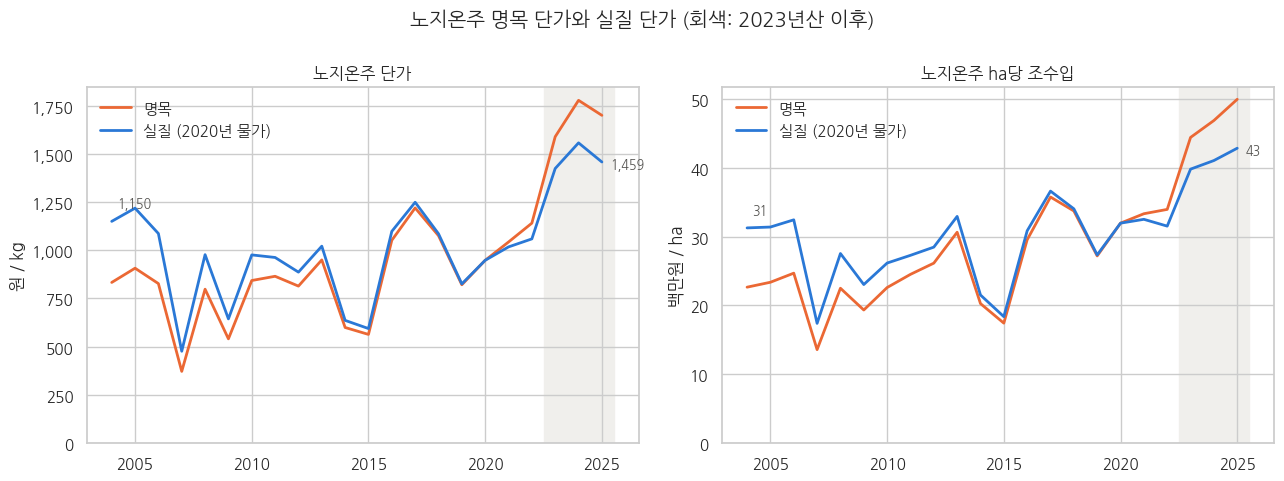

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (nom, real_col, unit, title) in zip(axes, [
    ("단가_원_kg", "실질단가_원_kg", "원 / kg", "노지온주 단가"),
    ("ha당_조수입_백만원", "실질_ha당_조수입_백만원", "백만원 / ha", "노지온주 ha당 조수입"),
]):
    ax.plot(n.index, n[nom], color=C2, linewidth=2, label="명목")
    ax.plot(n.index, n[real_col], color=C1, linewidth=2, label="실질 (2020년 물가)")
    ax.axvspan(2022.5, 2025.5, color="#f0efec", zorder=0)
    ax.annotate(f"{n.loc[2025, real_col]:,.0f}", (2025, n.loc[2025, real_col]), xytext=(6, -4),
                textcoords="offset points", fontsize=9, color=MUTED)
    ax.annotate(f"{n.loc[2004, real_col]:,.0f}", (2004, n.loc[2004, real_col]), xytext=(4, 10),
                textcoords="offset points", fontsize=9, color=MUTED)
    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    ax.set_ylim(bottom=0)
    ax.legend(loc="upper left", frameon=False)
fig.suptitle("노지온주 명목 단가와 실질 단가 (회색: 2023년산 이후)", y=1.0)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_noji_real_vs_nominal.png", dpi=150)
plt.show()

**관찰**

- Slack 중간 보고서 수치를 그대로 재현했습니다. 실질 단가 **+26.8%**(2004→2025), **+16.8%**(2017→2025), 실질 ha당 조수입 **+37.1%**, **+17.0%**.
- 3년 평균끼리 비교해도 실질 단가 +28%, ha당 조수입 +30%로 비슷합니다. 시작·끝 연도를 고른 효과는 아닙니다.
- **새로 확인한 점**: 2004→2022년만 보면 실질 단가는 **−8%**, ha당 조수입은 **+1%** 로 거의 제자리입니다. 장기 실질 상승분은 대부분 **2023~2025년산 3개 시즌**에서 생겼습니다.
  이 3년은 `02`에서 본 폭염·저생산 시기와 겹칩니다. 따라서 "구조적 상승"이라기보다 **최근 공급 충격**일 가능성을 먼저 검토해야 합니다.
- 제주 노지온주 **총 조수입**은 실질 기준으로 2004→2025년 **−2.9%** 입니다. 면적이 29% 줄어서, ha당 실질 매출이 늘어난 효과가 상쇄됐습니다.

### 2.2 2017년 재배면적 단절 (품질 이슈 Q9)

노지온주 면적은 2016→2017년에 16,610ha → 15,006ha(−9.7%)로 한 번에 줄었습니다. 이 단절은 이미 [`requirements_spec.md`](../docs/requirements_spec.md) §4의 **Q9**로 확인했습니다.
면적·농가수만 크게 바뀌고 생산량은 거의 그대로이므로, 통계 기준(재조사·품종 재분류)이 바뀐 것으로 봅니다. 여기서는 물가 보정 분석에 주는 영향만 다시 정리합니다.

In [11]:
from jeju_citrus.data.quality_checks import structural_break

structural_break(prod).set_index("품종").reindex(VARIETIES).style.format(precision=2)

,재배면적_ha_2016,재배면적_ha_2017,재배면적_ha_변화율,생산량_톤_2016,생산량_톤_2017,생산량_톤_변화율,재배농가_호_2016,재배농가_호_2017,재배농가_호_변화율
품종,,,,,,,,,
노지온주,16609.80,15006.00,-0.10,466817.00,440254.00,-0.06,22415.00,20259.00,-0.10
하우스온주,284.00,301.00,0.06,21660.00,22637.00,0.04,697.00,737.00,0.06
월동온주,1336.30,901.00,-0.33,37250.00,35012.00,-0.06,2374.00,1647.00,-0.31
한라봉,1454.00,1611.00,0.11,44500.00,44311.00,-0.00,3704.00,3667.00,-0.01
천혜향,346.00,872.00,1.52,13400.00,15700.00,0.17,986.00,1573.00,0.59
레드향,167.00,732.00,3.38,6460.00,8067.00,0.25,491.00,1396.00,1.84
황금향,98.10,351.00,2.58,3566.00,3600.00,0.01,305.00,793.00,1.60


**관찰**

- 같은 해 **레드향 +338%, 황금향 +258%, 천혜향 +152%** 로 면적이 늘었고, 노지온주 −10%, 월동온주 −33%로 줄었습니다. 2018·2019년에는 거의 그대로입니다.
- 이번에 추가로 확인한 근거: 2017년산 보고서 86쪽의 감귤 전체 면적은 20,491 → 20,140ha(−1.7%)로 거의 같습니다. 반면 만감류는 2,261 → 3,932ha(+74%)입니다. 전체는 그대로이고 품종 사이에서 면적이 옮겨갔으므로 **재분류**라는 Q9 판단과 맞습니다.
- 보고서와 jasdc 화면에는 변경 이유가 적혀 있지 않습니다. 확정하려면 제주도 감귤유통과에 확인해야 합니다.

**분석에 주는 영향**: 2017년 전후의 **ha당 지표**(면적으로 나눈 값)는 그대로 이어 붙이면 안 됩니다. 단가(원/kg)는 면적과 무관하므로 영향이 없습니다.

### 2.3 다른 품종도 실질 기준으로 올랐는가?

면적 단절을 피하려고 **2017~2019년 평균 → 2023~2025년 평균**으로 비교했습니다. 단가(면적과 무관)는 자료 시작 3년과도 비교했습니다.

In [12]:
out = []
for v, d in prod.groupby("품종"):
    d = d.sort_values("연도").set_index("연도")
    yrs = pd.Series(d.index, index=d.index)
    r_ha = deflate(d["ha당_조수입_백만원"], yrs, cpi)
    r_pr = deflate(d["단가_원_kg"], yrs, cpi)
    if 2017 not in d.index:
        continue
    recent = slice(2023, 2025)
    out.append({
        "품종": v,
        "실질 ha당 2017~19": r_ha.loc[2017:2019].mean(),
        "실질 ha당 2023~25": r_ha.loc[recent].mean(),
        "ha당 변화율 % (2017~19 대비)": (r_ha.loc[recent].mean() / r_ha.loc[2017:2019].mean() - 1) * 100,
        "실질 단가 변화율 % (2017~19 대비)": (r_pr.loc[recent].mean() / r_pr.loc[2017:2019].mean() - 1) * 100,
        "실질 단가 변화율 % (자료 시작 3년 대비)": (r_pr.loc[recent].mean() / r_pr.iloc[:3].mean() - 1) * 100,
    })
pd.DataFrame(out).set_index("품종").reindex(VARIETIES).round(1)

,실질 ha당 2017~19,실질 ha당 2023~25,ha당 변화율 % (2017~19 대비),실질 단가 변화율 % (2017~19 대비),실질 단가 변화율 % (자료 시작 3년 대비)
품종,,,,,
노지온주,32.7,41.3,26.3,40.5,28.5
하우스온주,266.2,192.2,-27.8,-6.4,-14.0
월동온주,89.1,99.6,11.8,42.1,28.5
한라봉,80.7,87.2,8.0,15.1,-32.5
천혜향,72.1,119.9,66.4,0.1,-26.9
레드향,61.3,98.0,59.9,-1.3,-3.1
황금향,32.3,72.4,124.0,-2.7,-32.0


**관찰**

- 처음에는 "레드향 −43%, 황금향 −28%"로 계산됐습니다(자료 시작 3년 대비 ha당 조수입). 하지만 이 값은 **2017년 면적 단절 때문에 생긴 착시**였습니다.
  2017년 이전에는 면적이 작게 잡혀 ha당 값이 부풀려져 있었습니다. 단절 이후 기준으로 보면 레드향 **+60%**, 황금향 **+124%**, 천혜향 **+66%** 로 오히려 늘었습니다.
  같은 기간 실질 단가는 거의 그대로이므로(−3~0%), **ha당 매출 증가는 단위면적당 생산량 증가**에서 나왔습니다. 2017년 무렵 새로 심은 과원이 자라 수확량이 늘어난 결과로 보입니다.
- 노지온주(+26%)와 월동온주(+12%)는 실질 단가가 40% 이상 오르면서 ha당 매출이 늘었습니다.
- **하우스온주만 ha당 실질 매출이 줄었습니다(−28%)**. 1.2에서 본 표준표 실질 소득 감소와 같은 방향입니다.

### 2.4 생산비 물가로 보정하면?

CPI는 **소비자 생활물가**입니다. 농가가 실제로 내는 비료·농약·인건비 가격은 따로 움직입니다.
KOSIS 「농가판매 및 구입가격조사」의 **농가구입가격지수**(2020=100, 분기 → 연평균, 2005년부터)로 다시 보정했습니다.

- **농가구입 총지수**: 가계용품(생활비)까지 포함한 전체 지수
- **노지 경영비지수**: 2024년산 노지감귤 표준소득표의 경영비 세부 항목 15개를 농가구입가격지수 하위 지수 8개(비료비·농약비·영농자재비·노무비·영농광열비·임차료·경비·자산구입비)에 짝지어 가중평균한 값. 노지 농가의 비용 구성에 맞춘 지수입니다(추정).

In [13]:
farm = load_farm_purchase_index()

# 2024년산 노지감귤 표준소득 분석표 경영비 세부 항목 (원/10a, scripts/extract_standard_income.py로 추출)
items = load_standard_income_items()
noji_cost_2024 = items.query("산지연도 == 2024 and 대응품종 == '노지온주'")[
    [i for g in COST_ITEM_GROUPS.values() for i in g]].iloc[0].to_dict()
w_noji = cost_weights(noji_cost_2024)
print("노지 경영비 가중치:", {k: round(v, 3) for k, v in w_noji.items()})

deflators = pd.DataFrame({
    "CPI": cpi.set_index("연도")["CPI_2020_100"],
    "농가구입 총지수": farm["총지수"],
    "노지 경영비지수": cost_price_index(farm, w_noji),
}).loc[2005:2025]
sub = farm.loc[[2005, 2017, 2020, 2022, 2025], ["비료비", "농약비", "영농자재비", "노무비", "영농광열비", "경비", "자산구입비"]]
display(pd.concat([deflators.loc[[2005, 2017, 2020, 2022, 2025]], sub], axis=1).round(1))

노지 경영비 가중치: {'비료비': 0.093, '농약비': 0.223, '영농자재비': 0.057, '노무비': 0.273, '영농광열비': 0.03, '임차료': 0.063, '경비': 0.03, '자산구입비': 0.23}


,CPI,농가구입 총지수,노지 경영비지수,비료비,농약비,영농자재비,노무비,영농광열비,경비,자산구입비
연도,,,,,,,,,,
2005,74.4,70.8,65.7,74.8,54.2,82.1,47.5,111.4,92.3,81.2
2017,97.6,95.1,90.4,96.5,81.5,95.8,87.6,108.1,94.8,96.6
2020,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2022,107.7,120.1,128.8,249.6,109.5,141.9,122.9,201.7,133.1,99.1
2025,116.6,121.6,132.5,169.1,132.0,142.0,137.9,168.0,130.2,106.0


In [14]:
rows = []
for dname in ["명목"] + list(deflators.columns):
    for col, label in [("단가_원_kg", "단가"), ("ha당_조수입_백만원", "ha당 조수입")]:
        s = n.loc[2005:2025, col]
        if dname != "명목":
            s = s / deflators[dname] * 100
        rows.append({
            "지표": label, "보정": dname,
            "2005→2025": (s[2025] / s[2005] - 1) * 100,
            "2017→2025": (s[2025] / s[2017] - 1) * 100,
            "2005→2022": (s[2022] / s[2005] - 1) * 100,
        })
pd.DataFrame(rows).set_index(["지표", "보정"]).round(1)

,,2005→2025,2017→2025,2005→2022
지표,보정,,,
단가,명목,87.5,39.4,25.8
ha당 조수입,명목,114.0,39.8,45.4
단가,CPI,19.7,16.8,-13.1
ha당 조수입,CPI,36.5,17.0,0.4
단가,농가구입 총지수,9.1,9.0,-25.9
ha당 조수입,농가구입 총지수,24.5,9.3,-14.4
단가,노지 경영비지수,-7.0,-4.9,-35.8
ha당 조수입,노지 경영비지수,6.2,-4.6,-25.8


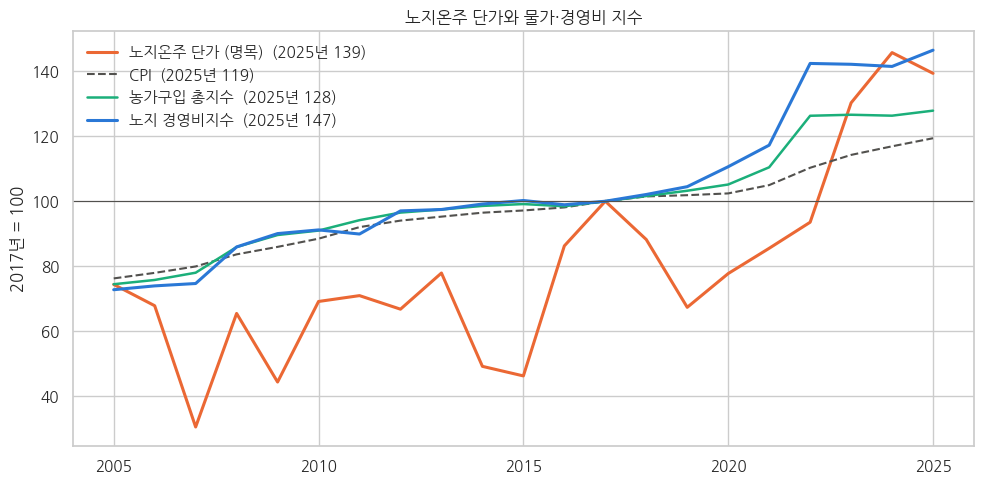

In [15]:
base = 2017
lines = pd.DataFrame({
    "노지온주 단가 (명목)": n.loc[2005:2025, "단가_원_kg"],
    "CPI": deflators["CPI"],
    "농가구입 총지수": deflators["농가구입 총지수"],
    "노지 경영비지수": deflators["노지 경영비지수"],
})
lines = lines / lines.loc[base] * 100
fig, ax = plt.subplots(figsize=(10, 5))
for (name, s), color, lw in zip(lines.items(), [C2, MUTED, C3, C1], [2.2, 1.5, 1.8, 2.2]):
    ax.plot(s.index, s.values, color=color, linewidth=lw, label=f"{name}  (2025년 {s[2025]:.0f})",
            linestyle="--" if name == "CPI" else "-")
ax.axhline(100, color=MUTED, linewidth=0.8)
ax.xaxis.set_major_locator(mticker.MultipleLocator(5))
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d"))
ax.set_ylabel(f"{base}년 = 100")
ax.set_title("노지온주 단가와 물가·경영비 지수")
ax.legend(loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_noji_price_vs_cost_index.png", dpi=150)
plt.show()

**관찰**

- 2005→2025년 CPI는 +57%였지만 **노지 경영비지수는 2.0배**(+102%)가 됐습니다. 노지 경영비에서 비중이 큰 **노무비(27%)는 2.9배**(47.5 → 137.9), **농약비(22%)는 2.4배**가 됐습니다. 2022년에는 비료비가 2020년의 2.5배까지 뛰었습니다.
- 그래서 같은 노지온주 단가라도 **무엇으로 나누느냐에 따라 결론이 바뀝니다**. 2017→2025년 실질 단가는 CPI 기준 +16.8%, 농가구입 총지수 기준 +9.0%, **노지 경영비지수 기준 −4.9%** 입니다. ha당 조수입도 +17.0% → +9.3% → **−4.6%** 입니다.
- 즉 **최근 노지온주 가격 상승은 생활물가보다는 빨랐지만, 농사 비용 상승을 따라잡지 못했습니다**. 2.1의 "물가를 빼도 올랐다"는 결론은 소비자 구매력 기준에서만 맞습니다.
- 2005→2022년만 보면 노지 경영비지수 기준 실질 단가는 −35.8%입니다. 2023~2025년산 고가격이 아니었다면 비용 대비 가격은 크게 나빠진 상태였습니다.
- 1.2의 표준표 실질 소득에서 노지온주가 9년 동안 추세 없이 오르내린 것과도 맞는 결과입니다.

**한계**: 노지 경영비지수의 가중치는 2024년산 한 해의 비용 구성입니다(2017년산 구성으로 바꿔도 결론의 방향은 같은지 04 노트북에서 확인). 상각비(대농구·영농시설·과수원조성)는 실제로는 과거 구입 가격을 나눠 반영하는 값이라, 자산구입비 지수로 대신한 것은 근사입니다. 자가노동비는 경영비에 들어가지 않으므로 가중치에서 빠져 있습니다. 2004년은 지수가 없어 2005년부터 비교했고, 2005년 노지온주 단가는 처리량 기준 값입니다(품질 이슈 Q8).

### 2장 한계

- 2.1~2.3은 CPI(소비자 구매력) 기준입니다. 생산비 기준 보정은 2.4에서 노지온주만 했습니다. 만감류·시설은 비용 구성이 달라(시설은 수도광열비 비중이 큼) 품종별 경영비지수를 따로 만들어야 합니다.
- 2017년 면적 단절의 원인은 추정입니다(2.2).
- 품질·규격·판매경로 구성 변화는 분리하지 않았습니다.

## 요약

| 질문 | 답 | 확신도 |
| --- | --- | --- |
| 경영비를 빼면 어느 품종 소득이 높은가? | 하우스온주가 9년 중 6년 1위지만 실질 소득은 계속 감소. **천혜향은 9년 모두 2위 안**, 최근 3년 중 2년 1위 | 표준표 기준 중간 |
| 노지온주는 비용을 빼도 낮은가? | 예. 9년 모두 꼴찌, 2019·2022년산은 생산비 차감 시 적자 | 높음 |
| 표준표 소득을 제주 평균 농가로 볼 수 있나? | 만감류는 아님. 표준표 총수입이 9년 내내 제주 평균의 1.14~3.71배 | 높음 |
| 노지온주 가격 상승은 물가 때문만인가? | 생활물가(CPI) 기준으로는 아니오(실질 단가 2004→2025 +27%). 하지만 **노지 경영비 물가 기준으로는 2017→2025 −5%로 오히려 하락**. 상승분은 2023~2025년산에 몰려 있음 | 구간 변화율은 높음, 경영비지수는 추정 |
| 만감류 ha당 매출은 실질 기준으로 줄었나? | 아니오. 줄어 보인 것은 2017년 면적 단절 때문. 단절 이후 레드향·황금향·천혜향 모두 증가 | 중간 (단절 원인은 추정) |
| 하우스온주 수익성은? | 실질 ha당 매출(−28%)과 표준표 실질 소득(159→96) 모두 감소 | 중간 |